# Text Similarity

## Anggota Kelompok
- Najla Zahira (25031554041)
- Moza Athaillah Azzahra (25031554185)

Dataset
https://drive.google.com/file/d/1Lioi1yyYc44BMFIfFMDilfjPqPDDxrZC/view?usp=sharing

## Step 1 — Load dan Validasi Dataset

Pada tahap ini, dataset hasil feature engineering dari Exercise 5 dimuat dan diperiksa sebelum digunakan dalam perhitungan text similarity. Pemeriksaan meliputi jumlah dokumen, struktur kolom, kelengkapan metadata, serta validitas fitur TF-IDF untuk memastikan dataset siap dianalisis.

In [ ]:
import pandas as pd
import numpy as np

# Load dataset hasil Exercise 5
df = pd.read_csv('hasil_tfidf.csv')

# Kolom metadata
metadata_cols = ['no', 'judul', 'topik']

# Validasi keberadaan kolom metadata
missing_cols = [col for col in metadata_cols if col not in df.columns]

if missing_cols:
    raise ValueError(f"Kolom metadata tidak ditemukan: {missing_cols}")

# Pisahkan kolom metadata dan fitur TF-IDF
feature_cols = [col for col in df.columns if col not in metadata_cols]

# Informasi dasar dataset
print("=== INFORMASI DATASET EXERCISE 5 ===")
print(f"Jumlah dokumen       : {df.shape[0]}")
print(f"Jumlah seluruh kolom : {df.shape[1]}")
print(f"Jumlah kolom metadata: {len(metadata_cols)}")
print(f"Jumlah fitur TF-IDF  : {len(feature_cols)}")

# Pemeriksaan metadata
print("\n=== PEMERIKSAAN METADATA ===")
print(df[metadata_cols].isnull().sum())

# Pemeriksaan fitur TF-IDF
X_df = df[feature_cols]

print("\n=== PEMERIKSAAN FITUR TF-IDF ===")
print("Seluruh fitur numerik:", all(
    pd.api.types.is_numeric_dtype(X_df[col])
    for col in feature_cols
))
print("Jumlah nilai kosong:", X_df.isnull().sum().sum())

X_values = X_df.to_numpy(dtype=float)

print("Seluruh nilai finite:", np.isfinite(X_values).all())
print("Jumlah baris dengan seluruh fitur nol:",
      np.sum(np.all(X_values == 0, axis=1)))

# Tampilkan sampel metadata
print("\n=== CONTOH DOKUMEN ===")
display(df[metadata_cols].head())

=== INFORMASI DATASET EXERCISE 5 ===
Jumlah dokumen       : 100
Jumlah seluruh kolom : 1503
Jumlah kolom metadata: 3
Jumlah fitur TF-IDF  : 1500

=== PEMERIKSAAN METADATA ===
no       0
judul    0
topik    0
dtype: int64

=== PEMERIKSAAN FITUR TF-IDF ===
Seluruh fitur numerik: True
Jumlah nilai kosong: 0
Seluruh nilai finite: True
Jumlah baris dengan seluruh fitur nol: 0

=== CONTOH DOKUMEN ===


,no,judul,topik
0,1,Algoritma bias,Computer Science
1,2,Algoritma Lanczos,Computer Science
2,3,ASCII,Computer Science
3,4,Karakter null,Computer Science
4,5,Komputasi optis,Computer Science


## Step 2 — Memisahkan Metadata dan Matriks Fitur

Pada tahap ini, metadata dokumen dipisahkan dari fitur numerik TF-IDF. Matriks fitur hanya berisi bobot TF-IDF yang digunakan untuk menghitung Cosine Similarity, sedangkan nomor, judul, dan topik artikel disimpan untuk membantu mengidentifikasi serta menginterpretasikan hasil perhitungan.

In [ ]:
# Memisahkan metadata dokumen
metadata = df[['no', 'judul', 'topik']].copy().reset_index(drop=True)

# Mengambil hanya fitur TF-IDF
X_df = df[feature_cols].copy()

# Mengubah fitur menjadi matriks numerik
X = X_df.to_numpy(dtype=float)

# Menampilkan informasi matriks
print("=== MATRIKS FITUR UNTUK COSINE SIMILARITY ===")
print(f"Jumlah dokumen : {X.shape[0]}")
print(f"Jumlah fitur   : {X.shape[1]}")
print(f"Ukuran matriks : {X.shape}")

print("\n=== CONTOH METADATA ===")
display(metadata.head())

print("\n=== CONTOH MATRIKS FITUR ===")
display(X_df.iloc[:5, :10])

=== MATRIKS FITUR UNTUK COSINE SIMILARITY ===
Jumlah dokumen : 100
Jumlah fitur   : 1500
Ukuran matriks : (100, 1500)

=== CONTOH METADATA ===


,no,judul,topik
0,1,Algoritma bias,Computer Science
1,2,Algoritma Lanczos,Computer Science
2,3,ASCII,Computer Science
3,4,Karakter null,Computer Science
4,5,Komputasi optis,Computer Science



=== CONTOH MATRIKS FITUR ===


,000,01,02,03,05,07,10,100,11,12
0,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
1,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
2,0.000000,0.0,0.0,0.0,0.0,0.0,0.021201,0.0,0.0,0.0
3,0.031423,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
4,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0


## Step 3 — Menghitung Cosine Similarity

Cosine Similarity digunakan untuk mengukur kemiripan antara representasi TF-IDF setiap dokumen. Perhitungan dilakukan menggunakan matriks fitur `X`, yang hanya berisi bobot TF-IDF dan tidak menyertakan metadata seperti judul maupun topik artikel.

Hasil perhitungan berupa matriks kemiripan berukuran 100 × 100. Setiap baris dan kolom mewakili satu dokumen, sedangkan setiap elemen menunjukkan nilai kemiripan antara pasangan dokumen tersebut.

In [ ]:

from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

# Menghitung kemiripan antarsemua dokumen
similarity_matrix = cosine_similarity(X)

# Menampilkan ukuran matriks kemiripan
print("=== HASIL COSINE SIMILARITY ===")
print("Jumlah dokumen :", similarity_matrix.shape[0])
print("Ukuran matriks :", similarity_matrix.shape)

# Menampilkan judul dokumen untuk membantu membaca hasil
print("\n=== DAFTAR 5 DOKUMEN PERTAMA ===")
display(metadata[['no', 'judul']].head())

# Menampilkan sebagian matriks kemiripan (5 x 5)
doc_labels = [f"Dokumen {n}" for n in metadata['no']]

similarity_preview = pd.DataFrame(
    similarity_matrix[:5, :5],
    index=doc_labels[:5],
    columns=doc_labels[:5]
)

print("\n=== CONTOH MATRIKS KEMIRIPAN (5 x 5) ===")
display(similarity_preview.round(3))


=== HASIL COSINE SIMILARITY ===
Jumlah dokumen : 100
Ukuran matriks : (100, 100)

=== DAFTAR 5 DOKUMEN PERTAMA ===


,no,judul
0,1,Algoritma bias
1,2,Algoritma Lanczos
2,3,ASCII
3,4,Karakter null
4,5,Komputasi optis



=== CONTOH MATRIKS KEMIRIPAN (5 x 5) ===


,Dokumen 1,Dokumen 2,Dokumen 3,Dokumen 4,Dokumen 5
Dokumen 1,1.000,0.232,0.035,0.015,0.048
Dokumen 2,0.232,1.000,0.025,0.010,0.029
Dokumen 3,0.035,0.025,1.000,0.329,0.015
Dokumen 4,0.015,0.010,0.329,1.000,0.011
Dokumen 5,0.048,0.029,0.015,0.011,1.000


## Step 4 — Memvalidasi Matriks Cosine Similarity

Validasi dilakukan untuk memastikan bahwa matriks kemiripan memiliki ukuran yang sesuai, bersifat simetris, memiliki nilai diagonal mendekati 1, serta tidak mengandung nilai yang tidak valid seperti NaN atau tak hingga.

Tahap ini penting untuk memastikan bahwa matriks hasil perhitungan dapat digunakan pada proses analisis kemiripan dokumen berikutnya.

In [ ]:

import numpy as np

# 1. Memeriksa ukuran matriks
print("=== VALIDASI MATRIKS ===")
print("Ukuran matriks:", similarity_matrix.shape)
print("Jumlah nilai NaN:", np.isnan(similarity_matrix).sum())
print("Jumlah nilai tak hingga:", np.isinf(similarity_matrix).sum())

# 2. Memeriksa simetri matriks
is_symmetric = np.allclose(
    similarity_matrix,
    similarity_matrix.T,
    atol=1e-10
)
print("Matriks simetris:", is_symmetric)

# 3. Memeriksa nilai diagonal
diagonal = np.diag(similarity_matrix)
print("Diagonal mendekati 1:",
      np.allclose(diagonal, 1.0, atol=1e-6))
print("Nilai diagonal minimum:", diagonal.min())
print("Nilai diagonal maksimum:", diagonal.max())

# 4. Memeriksa rentang nilai kemiripan
print("Nilai minimum matriks:", similarity_matrix.min())
print("Nilai maksimum matriks:", similarity_matrix.max())

# 5. Memeriksa apakah seluruh nilai valid
is_finite = np.isfinite(similarity_matrix).all()
print("Semua nilai berhingga:", is_finite)


=== VALIDASI MATRIKS ===
Ukuran matriks: (100, 100)
Jumlah nilai NaN: 0
Jumlah nilai tak hingga: 0
Matriks simetris: True
Diagonal mendekati 1: True
Nilai diagonal minimum: 0.9999999999999983
Nilai diagonal maksimum: 1.0000000000000027
Nilai minimum matriks: 0.0032281741235679453
Nilai maksimum matriks: 1.0000000000000027
Semua nilai berhingga: True


## Step 5 — Menemukan Pasangan Dokumen dengan Kemiripan Tertinggi

Tahap ini bertujuan menemukan pasangan dokumen yang memiliki nilai Cosine Similarity tertinggi. Nilai diagonal dikecualikan agar dokumen tidak dibandingkan dengan dirinya sendiri. Selain itu, hanya satu bagian matriks yang digunakan untuk menghindari pasangan terduplikasi akibat sifat simetris matriks kemiripan.

Hasilnya digunakan untuk mengidentifikasi artikel-artikel yang memiliki kemiripan fitur TF-IDF paling tinggi dalam dataset.

In [ ]:

import numpy as np
import pandas as pd

# Mengambil indeks segitiga atas tanpa diagonal
# agar setiap pasangan dokumen hanya dihitung sekali
upper_i, upper_j = np.triu_indices(
    similarity_matrix.shape[0],
    k=1
)

# Mengambil nilai kemiripan dari pasangan yang dipilih
similarity_values = similarity_matrix[upper_i, upper_j]

# Membuat tabel seluruh pasangan dokumen
pairs_df = pd.DataFrame({
    'dokumen_1': metadata['judul'].iloc[upper_i].to_numpy(),
    'topik_1': metadata['topik'].iloc[upper_i].to_numpy(),
    'dokumen_2': metadata['judul'].iloc[upper_j].to_numpy(),
    'topik_2': metadata['topik'].iloc[upper_j].to_numpy(),
    'cosine_similarity': similarity_values
})

# Mengurutkan pasangan berdasarkan kemiripan tertinggi
pairs_df = pairs_df.sort_values(
    by='cosine_similarity',
    ascending=False
).reset_index(drop=True)

# Menampilkan 10 pasangan teratas
top_10_pairs = pairs_df.head(10).copy()
top_10_pairs['cosine_similarity'] = (
    top_10_pairs['cosine_similarity'].round(4)
)

print("=== 10 PASANGAN DOKUMEN PALING MIRIP ===")
display(top_10_pairs)


=== 10 PASANGAN DOKUMEN PALING MIRIP ===


,dokumen_1,topik_1,dokumen_2,topik_2,cosine_similarity
0,Enkripsi surel,Technology & Internet,Perangkat lunak enkripsi,Technology & Internet,0.6658
1,Halusinasi (kecerdasan buatan),AI,Keamanan kecerdasan buatan,AI,0.5372
2,Kecerdasan buatan,AI,Keamanan kecerdasan buatan,AI,0.5325
3,Etika informasi,Technology & Internet,Etika siber,Technology & Internet,0.5222
4,Ilmu komputer,Computer Science,Ilmu data,Data & Statistics,0.5160
5,Kecerdasan buatan,AI,Halusinasi (kecerdasan buatan),AI,0.4859
6,Kecerdasan buatan,AI,Kecerdasan buatan generatif,AI,0.4853
7,Normalisasi pangkalan data,Data & Statistics,Pangkalan data berorientasi dokumen,Data & Statistics,0.4792
8,Model teks-ke-gambar,AI,Stable Diffusion,AI,0.4781
9,Algoritma bias,Computer Science,Etika dalam kecerdasan buatan,AI,0.4767


## Step 6 — Menemukan Pasangan Dokumen dengan Kemiripan Terendah

Tahap ini bertujuan mengidentifikasi pasangan dokumen dengan nilai Cosine Similarity terendah. Sama seperti tahap sebelumnya, diagonal matriks dan pasangan terduplikasi dikecualikan.

Hasilnya digunakan untuk mengamati pasangan artikel yang memiliki kemiripan fitur TF-IDF relatif rendah. Nilai yang rendah tidak selalu berarti kedua artikel tidak memiliki hubungan secara semantik, karena pengukuran ini bergantung pada fitur TF-IDF yang terbentuk dari dataset.

In [ ]:

# Mengurutkan pasangan dokumen dari kemiripan terendah
bottom_10_pairs = pairs_df.sort_values(
    by='cosine_similarity',
    ascending=True
).head(10).copy()

# Membulatkan skor agar mudah dibaca
bottom_10_pairs['cosine_similarity'] = (
    bottom_10_pairs['cosine_similarity'].round(4)
)

print("=== 10 PASANGAN DOKUMEN DENGAN KEMIRIPAN TERENDAH ===")
display(bottom_10_pairs)


=== 10 PASANGAN DOKUMEN DENGAN KEMIRIPAN TERENDAH ===


,dokumen_1,topik_1,dokumen_2,topik_2,cosine_similarity
4949,Membangkitkan Kombinasi,Computer Science,Komputasi neuromorfik,Computer Science,0.0032
4948,Agen otonom,AI,Modus (statistika),Data & Statistics,0.0037
4947,Pohon urai,Computer Science,Enkripsi surel,Technology & Internet,0.0041
4946,Karakter null,Computer Science,Agen otonom,AI,0.0046
4945,ASCII,Computer Science,Masalah pengendalian kecerdasan buatan,AI,0.0047
4944,Karakter null,Computer Science,Kesadaran buatan,AI,0.0048
4943,NURBS,Computer Science,Modus (statistika),Data & Statistics,0.0049
4942,Karakter null,Computer Science,Normalisasi pangkalan data,Data & Statistics,0.0050
4941,Pohon urai,Computer Science,Deep Web,Technology & Internet,0.0050
4940,ASCII,Computer Science,Pohon urai,Computer Science,0.0052


## Step 7 — Menginterpretasikan Hasil Kemiripan Dokumen

Interpretasi dilakukan dengan membandingkan nilai Cosine Similarity dan kategori topik dari pasangan dokumen yang memiliki kemiripan tertinggi maupun terendah. Analisis ini bertujuan mengamati apakah pasangan dengan skor tinggi cenderung memiliki kategori yang sama serta mengidentifikasi pengecualian yang muncul.

Kategori topik digunakan sebagai informasi pendukung setelah perhitungan kemiripan, bukan sebagai fitur dalam proses perhitungan. Oleh karena itu, hasil analisis menggambarkan kemiripan berdasarkan fitur TF-IDF, sedangkan kategori membantu memberikan konteks terhadap hasil tersebut.

In [ ]:

# Menandai apakah topik kedua dokumen dalam pasangan sama
pairs_df['topik_sama'] = (
    pairs_df['topik_1'] == pairs_df['topik_2']
)

# Ringkasan untuk 10 pasangan dengan kemiripan tertinggi
top_summary = top_10_pairs.copy()
top_summary['topik_sama'] = (
    top_summary['topik_1'] == top_summary['topik_2']
)

# Ringkasan untuk 10 pasangan dengan kemiripan terendah
bottom_summary = bottom_10_pairs.copy()
bottom_summary['topik_sama'] = (
    bottom_summary['topik_1'] == bottom_summary['topik_2']
)

print("=== ANALISIS 10 PASANGAN DENGAN KEMIRIPAN TERTINGGI ===")
print("Jumlah pasangan dengan topik sama:",
      top_summary['topik_sama'].sum(), "dari 10")
display(top_summary[
    ['dokumen_1', 'topik_1', 'dokumen_2',
     'topik_2', 'cosine_similarity', 'topik_sama']
])

print("\n=== ANALISIS 10 PASANGAN DENGAN KEMIRIPAN TERENDAH ===")
print("Jumlah pasangan dengan topik sama:",
      bottom_summary['topik_sama'].sum(), "dari 10")
display(bottom_summary[
    ['dokumen_1', 'topik_1', 'dokumen_2',
     'topik_2', 'cosine_similarity', 'topik_sama']
])


=== ANALISIS 10 PASANGAN DENGAN KEMIRIPAN TERTINGGI ===
Jumlah pasangan dengan topik sama: 8 dari 10


,dokumen_1,topik_1,dokumen_2,topik_2,cosine_similarity,topik_sama
0,Enkripsi surel,Technology & Internet,Perangkat lunak enkripsi,Technology & Internet,0.6658,True
1,Halusinasi (kecerdasan buatan),AI,Keamanan kecerdasan buatan,AI,0.5372,True
2,Kecerdasan buatan,AI,Keamanan kecerdasan buatan,AI,0.5325,True
3,Etika informasi,Technology & Internet,Etika siber,Technology & Internet,0.5222,True
4,Ilmu komputer,Computer Science,Ilmu data,Data & Statistics,0.5160,False
5,Kecerdasan buatan,AI,Halusinasi (kecerdasan buatan),AI,0.4859,True
6,Kecerdasan buatan,AI,Kecerdasan buatan generatif,AI,0.4853,True
7,Normalisasi pangkalan data,Data & Statistics,Pangkalan data berorientasi dokumen,Data & Statistics,0.4792,True
8,Model teks-ke-gambar,AI,Stable Diffusion,AI,0.4781,True
9,Algoritma bias,Computer Science,Etika dalam kecerdasan buatan,AI,0.4767,False



=== ANALISIS 10 PASANGAN DENGAN KEMIRIPAN TERENDAH ===
Jumlah pasangan dengan topik sama: 2 dari 10


,dokumen_1,topik_1,dokumen_2,topik_2,cosine_similarity,topik_sama
4949,Membangkitkan Kombinasi,Computer Science,Komputasi neuromorfik,Computer Science,0.0032,True
4948,Agen otonom,AI,Modus (statistika),Data & Statistics,0.0037,False
4947,Pohon urai,Computer Science,Enkripsi surel,Technology & Internet,0.0041,False
4946,Karakter null,Computer Science,Agen otonom,AI,0.0046,False
4945,ASCII,Computer Science,Masalah pengendalian kecerdasan buatan,AI,0.0047,False
4944,Karakter null,Computer Science,Kesadaran buatan,AI,0.0048,False
4943,NURBS,Computer Science,Modus (statistika),Data & Statistics,0.0049,False
4942,Karakter null,Computer Science,Normalisasi pangkalan data,Data & Statistics,0.0050,False
4941,Pohon urai,Computer Science,Deep Web,Technology & Internet,0.0050,False
4940,ASCII,Computer Science,Pohon urai,Computer Science,0.0052,True


## Step 8 — Visualisasi Matriks Cosine Similarity

Heatmap digunakan untuk memvisualisasikan matriks Cosine Similarity seluruh dokumen. Setiap sel menunjukkan nilai kemiripan antara dua dokumen, sedangkan gradasi warna membantu mengidentifikasi pola kemiripan yang relatif tinggi maupun rendah.

Visualisasi ini melengkapi tabel pasangan dokumen dengan memberikan gambaran umum mengenai distribusi kemiripan dalam dataset.

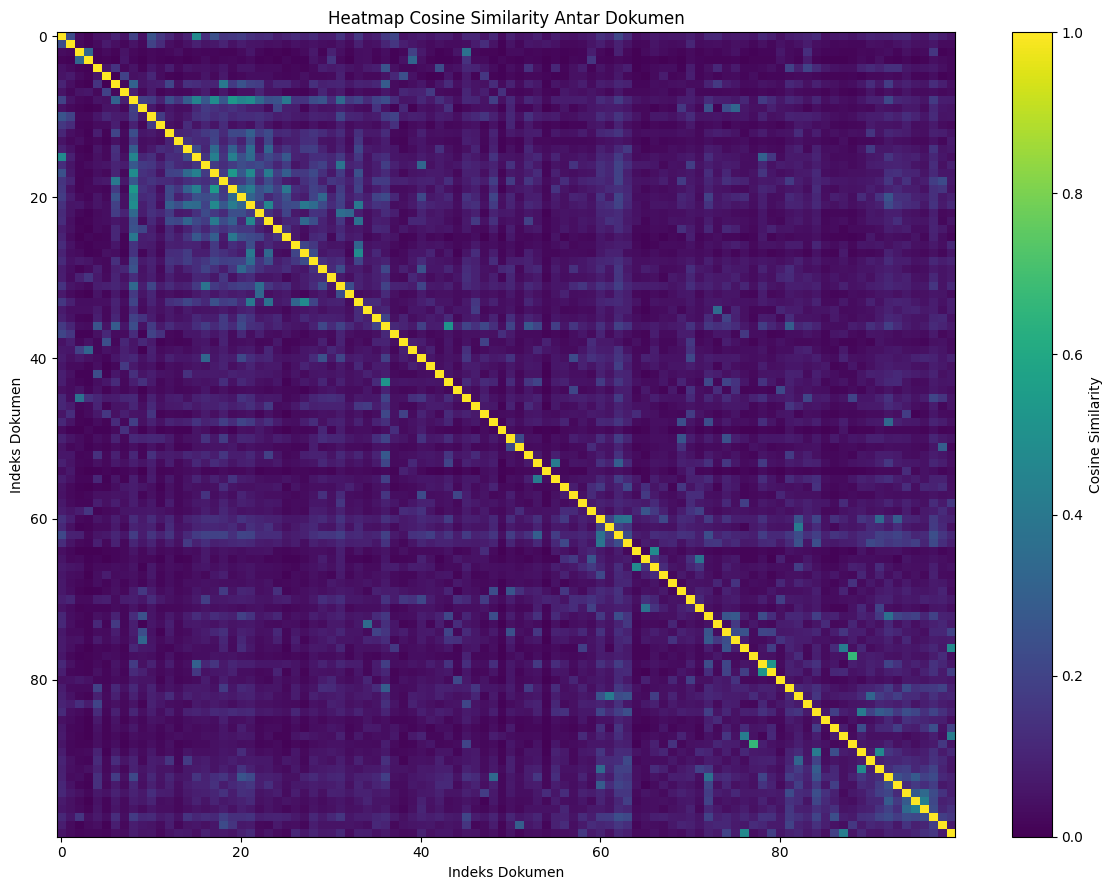

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 9))

plt.imshow(
    similarity_matrix,
    cmap='viridis',
    interpolation='nearest',
    aspect='auto',
    vmin=0,
    vmax=1
)

plt.colorbar(label='Cosine Similarity')
plt.title('Heatmap Cosine Similarity Antar Dokumen')
plt.xlabel('Indeks Dokumen')
plt.ylabel('Indeks Dokumen')

plt.tight_layout()
plt.show()


## Kesimpulan Exercise 6 — Text Similarity

Pada Exercise 6, metode Cosine Similarity diterapkan untuk mengukur kemiripan antarartikel berdasarkan fitur TF-IDF yang dihasilkan pada Exercise 5. Sebanyak 100 dokumen direpresentasikan dalam matriks fitur berukuran 100 × 1500, kemudian dibandingkan untuk menghasilkan matriks kemiripan berukuran 100 × 100.

Hasil validasi menunjukkan bahwa matriks bersifat simetris, nilai diagonal mendekati 1, serta tidak mengandung nilai NaN maupun tak hingga. Hal ini menunjukkan bahwa hasil perhitungan dapat digunakan untuk analisis lebih lanjut.

Dari hasil pengurutan pasangan dokumen, pasangan *Enkripsi surel* dan *Perangkat lunak enkripsi* memperoleh nilai Cosine Similarity tertinggi pada sepuluh pasangan teratas, yaitu 0,6658. Sebaliknya, pasangan *Membangkitkan Kombinasi* dan *Komputasi neuromorfik* memperoleh nilai terendah, yaitu 0,0032. Hasil tersebut menunjukkan bahwa kemiripan fitur TF-IDF dapat berbeda meskipun dokumen berasal dari kategori topik yang sama.

Analisis sepuluh pasangan teratas menemukan bahwa 8 pasangan memiliki kategori topik yang sama, sedangkan pada sepuluh pasangan terbawah hanya 2 pasangan yang memiliki kategori sama. Temuan ini menunjukkan bahwa kesamaan kategori sering ditemukan pada pasangan dengan kemiripan tinggi dalam kelompok yang diamati, tetapi kategori saja tidak cukup untuk menentukan tingkat kemiripan teks.

Visualisasi heatmap memperlihatkan diagonal utama dengan nilai mendekati 1 dan sebagian besar area di luar diagonal berwarna lebih gelap, dengan beberapa pasangan memiliki nilai kemiripan yang relatif lebih tinggi. Secara keseluruhan, Cosine Similarity berbasis TF-IDF dapat digunakan untuk mengidentifikasi pasangan artikel yang memiliki kemiripan pola fitur kata. Namun, skor yang dihasilkan tidak secara langsung mengukur kesamaan makna secara semantik karena bergantung pada representasi TF-IDF yang digunakan.